In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/shahliza27/ur-fall-detection-dataset/UR_fall_detection_dataset_cam0_rgb/adl-07-cam0-rgb/adl-07-cam0-rgb-057.png
/kaggle/input/datasets/shahliza27/ur-fall-detection-dataset/UR_fall_detection_dataset_cam0_rgb/adl-07-cam0-rgb/adl-07-cam0-rgb-034.png
/kaggle/input/datasets/shahliza27/ur-fall-detection-dataset/UR_fall_detection_dataset_cam0_rgb/adl-07-cam0-rgb/adl-07-cam0-rgb-178.png
/kaggle/input/datasets/shahliza27/ur-fall-detection-dataset/UR_fall_detection_dataset_cam0_rgb/adl-07-cam0-rgb/adl-07-cam0-rgb-126.png
/kaggle/input/datasets/shahliza27/ur-fall-detection-dataset/UR_fall_detection_dataset_cam0_rgb/adl-07-cam0-rgb/adl-07-cam0-rgb-002.png
/kaggle/input/datasets/shahliza27/ur-fall-detection-dataset/UR_fall_detection_dataset_cam0_rgb/adl-07-cam0-rgb/adl-07-cam0-rgb-103.png
/kaggle/input/datasets/shahliza27/ur-fall-detection-dataset/UR_fall_detection_dataset_cam0_rgb/adl-07-cam0-rgb/adl-07-cam0-rgb-153.png
/kaggle/input/datasets/shahliza27/ur-fall-detection-dat

In [3]:
!pip install -q opencv-python-headless scikit-learn seaborn tqdm

In [15]:
import os
import glob
import cv2
import numpy as np
import matplotlib.pyplot as plt

DATASET_DIR = (
    "/kaggle/input/datasets/"
    "shahliza27/ur-fall-detection-dataset/"
    "UR_fall_detection_dataset_cam0_rgb"
)

print("Dataset exists:", os.path.exists(DATASET_DIR))
print("Contents:", os.listdir(DATASET_DIR)[:10])

Dataset exists: True
Contents: ['adl-01-cam0-rgb', 'adl-02-cam0-rgb', 'adl-03-cam0-rgb', 'adl-04-cam0-rgb', 'adl-05-cam0-rgb', 'adl-06-cam0-rgb', 'adl-07-cam0-rgb', 'adl-08-cam0-rgb', 'adl-09-cam0-rgb', 'adl-10-cam0-rgb']


In [16]:
# Find all folders containing PNG frames

sequence_dirs = []

for root, dirs, files in os.walk(DATASET_DIR):

    png_files = [
        f for f in files
        if f.lower().endswith(".png")
    ]

    if len(png_files) > 0:
        sequence_dirs.append(root)


print("Total video sequences:", len(sequence_dirs))

print("\nFirst 15 sequences:")

for folder in sequence_dirs[:15]:
    print(os.path.basename(folder))

Total video sequences: 70

First 15 sequences:
adl-01-cam0-rgb
adl-02-cam0-rgb
adl-03-cam0-rgb
adl-04-cam0-rgb
adl-05-cam0-rgb
adl-06-cam0-rgb
adl-07-cam0-rgb
adl-08-cam0-rgb
adl-09-cam0-rgb
adl-10-cam0-rgb
adl-11-cam0-rgb
adl-12-cam0-rgb
adl-13-cam0-rgb
adl-14-cam0-rgb
adl-15-cam0-rgb


In [17]:
def get_label(folder):

    name = os.path.basename(folder).lower()

    if name.startswith("fall-"):
        return 1

    elif name.startswith("adl-"):
        return 0

    else:
        return None


fall_count = 0
adl_count = 0
unknown_count = 0

for folder in sequence_dirs:

    label = get_label(folder)

    if label == 1:
        fall_count += 1

    elif label == 0:
        adl_count += 1

    else:
        unknown_count += 1


print("Fall sequences:", fall_count)
print("ADL sequences:", adl_count)
print("Unknown sequences:", unknown_count)
print("Total:", len(sequence_dirs))

Fall sequences: 30
ADL sequences: 40
Unknown sequences: 0
Total: 70


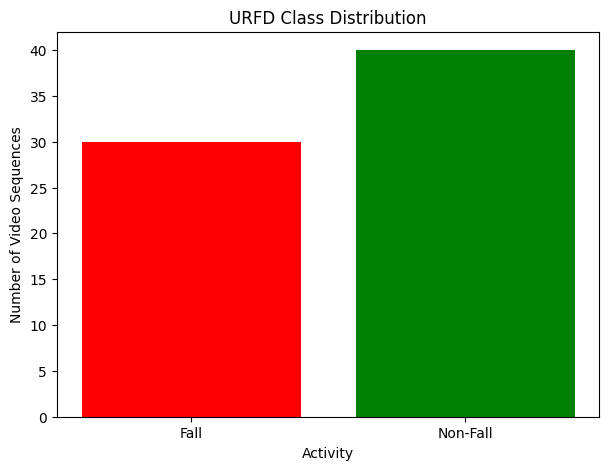

In [19]:
plt.figure(figsize=(7, 5))

plt.bar(
    ["Fall", "Non-Fall"],
    [fall_count, adl_count],
    color=["red", "green"]
)

plt.title("URFD Class Distribution")
plt.xlabel("Activity")
plt.ylabel("Number of Video Sequences")

plt.show()

In [23]:
IMG_SIZE = 112
NUM_FRAMES = 16


def extract_frames(folder):

    image_paths = sorted(
        glob.glob(os.path.join(folder, "*.png"))
    )

    if len(image_paths) == 0:
        return None

    # Select uniformly distributed frames
    indices = np.linspace(
        0,
        len(image_paths) - 1,
        NUM_FRAMES
    ).astype(int)

    frames = []

    for idx in indices:

        frame = cv2.imread(image_paths[idx])

        if frame is None:
            return None

        # Convert BGR to RGB
        frame = cv2.cvtColor(
            frame,
            cv2.COLOR_BGR2RGB
        )

        # Resize
        frame = cv2.resize(
            frame,
            (IMG_SIZE, IMG_SIZE)
        )

        frames.append(frame)

    return np.array(frames, dtype=np.uint8)

In [24]:
X = []
y = []
valid_paths = []
corrupted = []

for folder in sequence_dirs:

    label = get_label(folder)

    if label is None:
        continue

    try:

        frames = extract_frames(folder)

        if frames is None:
            corrupted.append(folder)
            continue

        if frames.shape != (16, 112, 112, 3):
            corrupted.append(folder)
            continue

        X.append(frames)
        y.append(label)
        valid_paths.append(folder)

    except Exception as e:

        print("Error:", folder, e)
        corrupted.append(folder)


X = np.array(X, dtype=np.uint8)
y = np.array(y, dtype=np.int64)

print("\nPreprocessing completed!")

print("Video tensor shape:", X.shape)
print("Labels shape:", y.shape)
print("Valid videos:", len(X))
print("Corrupted videos:", len(corrupted))

print("\nClass distribution:")

from collections import Counter

print(Counter(y))


Preprocessing completed!
Video tensor shape: (70, 16, 112, 112, 3)
Labels shape: (70,)
Valid videos: 70
Corrupted videos: 0

Class distribution:
Counter({np.int64(0): 40, np.int64(1): 30})


Fall video:


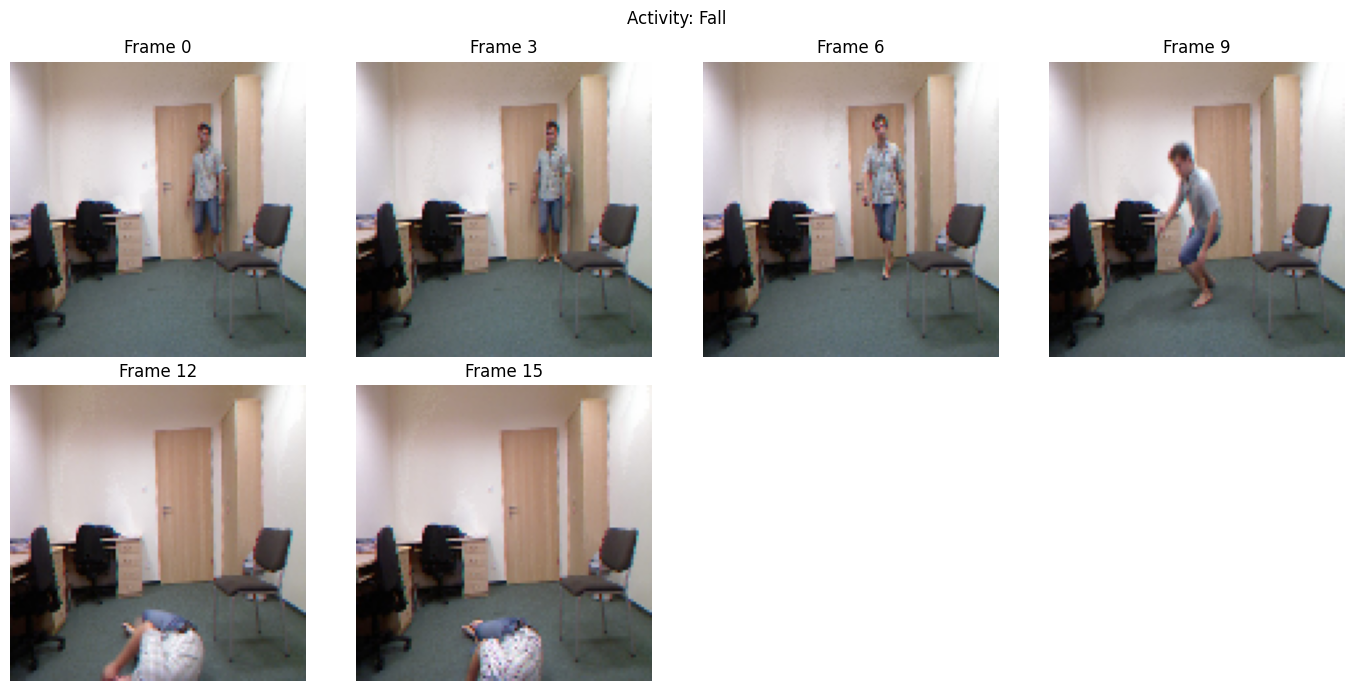

Non-Fall video:


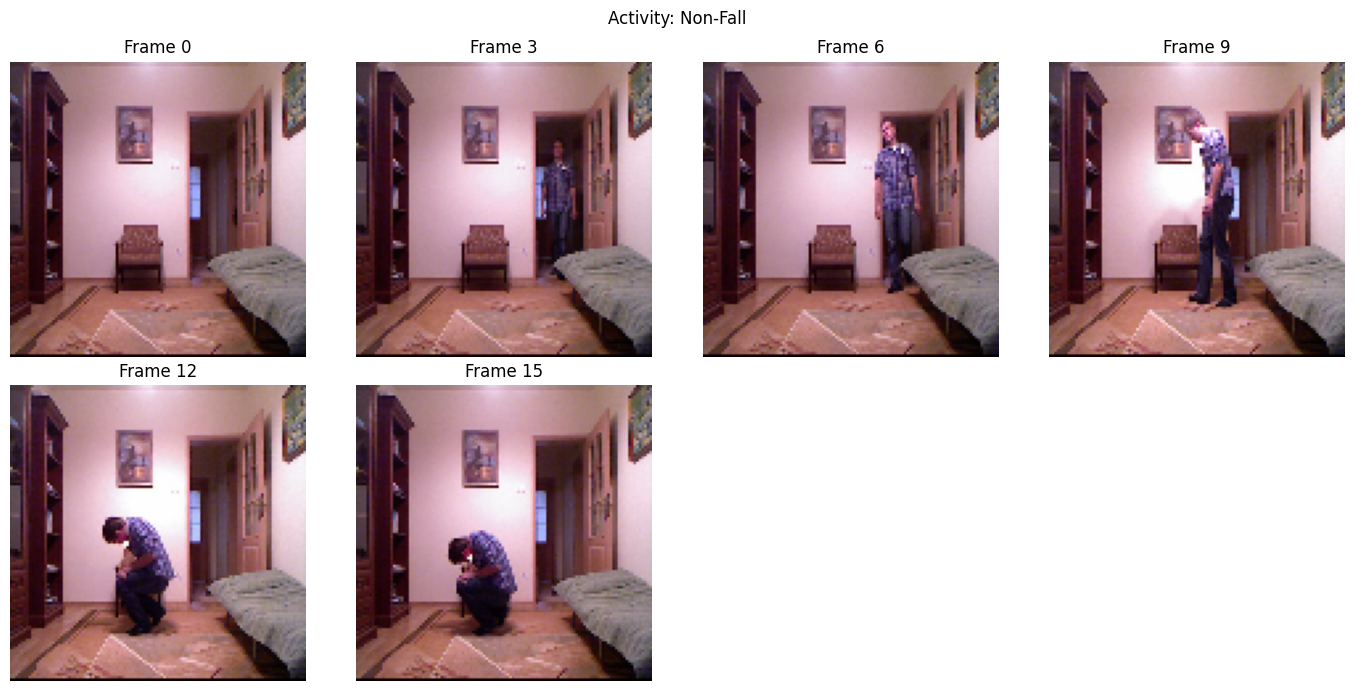

In [25]:
def visualize_video(index):

    video = X[index]

    fig, axes = plt.subplots(
        2, 4,
        figsize=(14, 7)
    )

    selected_frames = [0, 3, 6, 9, 12, 15]

    for i, frame_idx in enumerate(selected_frames):

        axes.flat[i].imshow(video[frame_idx])

        axes.flat[i].set_title(
            f"Frame {frame_idx}"
        )

        axes.flat[i].axis("off")

    for i in range(6, 8):
        axes.flat[i].axis("off")

    label = "Fall" if y[index] == 1 else "Non-Fall"

    plt.suptitle("Activity: " + label)

    plt.tight_layout()
    plt.show()


# Display one fall and one non-fall video

fall_indices = np.where(y == 1)[0]
adl_indices = np.where(y == 0)[0]

print("Fall video:")
visualize_video(fall_indices[0])

print("Non-Fall video:")
visualize_video(adl_indices[0])

In [26]:
import torch
import torch.nn as nn
import torch.optim as optim
import random
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve
)

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", DEVICE)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("GPU count:", torch.cuda.device_count())
else:
    print("GPU unavailable. Running on CPU.")

Device: cuda
GPU: Tesla T4
GPU count: 2


In [27]:
indices = np.arange(len(X))

# First split: 70% training, 30% remaining
train_idx, temp_idx = train_test_split(
    indices,
    test_size=0.30,
    random_state=SEED,
    stratify=y
)

# Second split: 15% validation, 15% testing
val_idx, test_idx = train_test_split(
    temp_idx,
    test_size=0.50,
    random_state=SEED,
    stratify=y[temp_idx]
)

X_train, y_train = X[train_idx], y[train_idx]

X_val, y_val = X[val_idx], y[val_idx]

X_test, y_test = X[test_idx], y[test_idx]

print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))
print("Testing samples:", len(X_test))

print("\nTraining distribution:", np.bincount(y_train))
print("Validation distribution:", np.bincount(y_val))
print("Testing distribution:", np.bincount(y_test))

Training samples: 49
Validation samples: 10
Testing samples: 11

Training distribution: [28 21]
Validation distribution: [6 4]
Testing distribution: [6 5]


In [28]:
class FallDataset(Dataset):

    def __init__(self, videos, labels, augment=False):

        self.videos = videos
        self.labels = labels
        self.augment = augment

    def __len__(self):
        return len(self.videos)

    def __getitem__(self, idx):

        video = self.videos[idx].copy()

        # Temporal jittering
        if self.augment:

            shift = random.choice([-1, 0, 1])

            if shift == 1:
                video = np.concatenate(
                    [video[:1], video[:-1]],
                    axis=0
                )

            elif shift == -1:
                video = np.concatenate(
                    [video[1:], video[-1:]],
                    axis=0
                )

            # Random horizontal flipping
            if random.random() < 0.5:

                video = np.flip(
                    video,
                    axis=2
                ).copy()

            # Random rotation
            if random.random() < 0.3:

                angle = random.uniform(-8, 8)

                matrix = cv2.getRotationMatrix2D(
                    (112 // 2, 112 // 2),
                    angle,
                    1.0
                )

                rotated_frames = []

                for frame in video:

                    rotated = cv2.warpAffine(
                        frame,
                        matrix,
                        (112, 112)
                    )

                    rotated_frames.append(rotated)

                video = np.array(rotated_frames)

        # Normalize pixels
        video = video.astype(np.float32) / 255.0

        # Convert T,H,W,C to C,T,H,W
        video = torch.from_numpy(video).permute(
            3, 0, 1, 2
        ).contiguous()

        label = torch.tensor(
            self.labels[idx],
            dtype=torch.long
        )

        return video, label

In [29]:
train_dataset = FallDataset(
    X_train,
    y_train,
    augment=True
)

val_dataset = FallDataset(
    X_val,
    y_val,
    augment=False
)

test_dataset = FallDataset(
    X_test,
    y_test,
    augment=False
)

# Calculate class weights
class_counts = np.bincount(
    y_train,
    minlength=2
)

class_weights = 1.0 / class_counts

sample_weights = class_weights[y_train]

sampler = WeightedRandomSampler(
    weights=torch.DoubleTensor(sample_weights),
    num_samples=len(sample_weights),
    replacement=True
)

BATCH_SIZE = 4

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    sampler=sampler,
    num_workers=2,
    pin_memory=(DEVICE.type == "cuda")
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=(DEVICE.type == "cuda")
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=(DEVICE.type == "cuda")
)

print("DataLoaders created successfully!")
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Testing batches:", len(test_loader))

DataLoaders created successfully!
Training batches: 13
Validation batches: 3
Testing batches: 3


In [30]:
class FallDetection3DCNN(nn.Module):

    def __init__(self, num_classes=2):

        super(FallDetection3DCNN, self).__init__()

        self.features = nn.Sequential(

            # Block 1
            nn.Conv3d(
                3, 16,
                kernel_size=3,
                padding=1
            ),

            nn.BatchNorm3d(16),
            nn.ReLU(inplace=True),

            nn.MaxPool3d(
                kernel_size=(1, 2, 2)
            ),

            # Block 2
            nn.Conv3d(
                16, 32,
                kernel_size=3,
                padding=1
            ),

            nn.BatchNorm3d(32),
            nn.ReLU(inplace=True),

            nn.MaxPool3d(2),

            # Block 3
            nn.Conv3d(
                32, 64,
                kernel_size=3,
                padding=1
            ),

            nn.BatchNorm3d(64),
            nn.ReLU(inplace=True),

            nn.MaxPool3d(2),

            # Block 4
            nn.Conv3d(
                64, 128,
                kernel_size=3,
                padding=1
            ),

            nn.BatchNorm3d(128),
            nn.ReLU(inplace=True),

            nn.AdaptiveAvgPool3d((1, 1, 1))
        )

        self.classifier = nn.Sequential(

            nn.Flatten(),

            nn.Dropout(0.5),

            nn.Linear(128, 64),

            nn.ReLU(inplace=True),

            nn.Dropout(0.3),

            nn.Linear(64, num_classes)
        )

    def forward(self, x):

        x = self.features(x)

        x = self.classifier(x)

        return x


model = FallDetection3DCNN().to(DEVICE)

print(model)

total_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print("\nTotal trainable parameters:", total_params)

FallDetection3DCNN(
  (features): Sequential(
    (0): Conv3d(3, 16, kernel_size=(3, 3, 3), stride=(1, 1, 1), padding=(1, 1, 1))
    (1): BatchNorm3d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): MaxPool3d(kernel_size=(1, 2, 2), stride=(1, 2, 2), padding=0, dilation=1, ceil_mode=False)
    (4): Conv3d(16, 32, kernel_size=(3, 3, 3), stride=(1, 1, 1), padding=(1, 1, 1))
    (5): BatchNorm3d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU(inplace=True)
    (7): MaxPool3d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv3d(32, 64, kernel_size=(3, 3, 3), stride=(1, 1, 1), padding=(1, 1, 1))
    (9): BatchNorm3d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU(inplace=True)
    (11): MaxPool3d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (12): Conv3d(64, 128, kernel_size=(3, 3, 3), stride=(1, 1, 1), padding=(1, 1, 

In [31]:
sample_video, sample_label = next(
    iter(train_loader)
)

sample_video = sample_video.to(DEVICE)

with torch.no_grad():

    output = model(sample_video)

print("Input shape:", sample_video.shape)
print("Output shape:", output.shape)

Input shape: torch.Size([4, 3, 16, 112, 112])
Output shape: torch.Size([4, 2])


In [32]:
criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=0.0001,
    weight_decay=1e-4
)

scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=3
)

EPOCHS = 30
PATIENCE = 7

scaler = torch.cuda.amp.GradScaler(
    enabled=(DEVICE.type == "cuda")
)

print("Training configuration ready!")

Training configuration ready!


/tmp/ipykernel_48/3237913258.py:19: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(


In [34]:
def train_one_epoch(model, loader):

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for videos, labels in loader:

        videos = videos.to(DEVICE)
        labels = labels.to(DEVICE)

        optimizer.zero_grad(set_to_none=True)

        with torch.cuda.amp.autocast(
            enabled=(DEVICE.type == "cuda")
        ):

            outputs = model(videos)

            loss = criterion(outputs, labels)

        scaler.scale(loss).backward()

        scaler.step(optimizer)

        scaler.update()

        running_loss += loss.item() * labels.size(0)

        predictions = torch.argmax(
            outputs,
            dim=1
        )

        correct += (
            predictions == labels
        ).sum().item()

        total += labels.size(0)

    epoch_loss = running_loss / total

    epoch_accuracy = correct / total

    return epoch_loss, epoch_accuracy

In [35]:
def validate(model, loader):

    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():

        for videos, labels in loader:

            videos = videos.to(DEVICE)
            labels = labels.to(DEVICE)

            with torch.cuda.amp.autocast(
                enabled=(DEVICE.type == "cuda")
            ):

                outputs = model(videos)

                loss = criterion(outputs, labels)

            running_loss += (
                loss.item() * labels.size(0)
            )

            predictions = torch.argmax(
                outputs,
                dim=1
            )

            correct += (
                predictions == labels
            ).sum().item()

            total += labels.size(0)

    return (
        running_loss / total,
        correct / total
    )

In [36]:
history = {
    "train_loss": [],
    "val_loss": [],
    "train_acc": [],
    "val_acc": []
}

best_val_loss = float("inf")
patience_counter = 0

MODEL_PATH = "/kaggle/working/best_3dcnn.pth"

for epoch in range(EPOCHS):

    train_loss, train_acc = train_one_epoch(
        model,
        train_loader
    )

    val_loss, val_acc = validate(
        model,
        val_loader
    )

    scheduler.step(val_loss)

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)

    history["train_acc"].append(train_acc)
    history["val_acc"].append(val_acc)

    print(
        f"Epoch [{epoch+1}/{EPOCHS}] "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f}"
    )

    if val_loss < best_val_loss:

        best_val_loss = val_loss

        patience_counter = 0

        torch.save(
            model.state_dict(),
            MODEL_PATH
        )

        print("Best model saved!")

    else:

        patience_counter += 1

    if patience_counter >= PATIENCE:

        print("Early stopping triggered!")
        break

print("\nTraining completed!")

/tmp/ipykernel_48/1930964048.py:16: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(


Epoch [1/30] Train Loss: 0.7055 | Train Acc: 0.4082 | Val Loss: 0.6764 | Val Acc: 0.6000
Best model saved!
Epoch [2/30] Train Loss: 0.6372 | Train Acc: 0.6531 | Val Loss: 0.6141 | Val Acc: 0.6000
Best model saved!
Epoch [3/30] Train Loss: 0.5514 | Train Acc: 0.7755 | Val Loss: 0.5272 | Val Acc: 0.8000
Best model saved!
Epoch [4/30] Train Loss: 0.4817 | Train Acc: 0.8776 | Val Loss: 0.4178 | Val Acc: 0.8000
Best model saved!
Epoch [5/30] Train Loss: 0.5334 | Train Acc: 0.6939 | Val Loss: 0.4415 | Val Acc: 0.8000
Epoch [6/30] Train Loss: 0.5523 | Train Acc: 0.7143 | Val Loss: 0.4783 | Val Acc: 0.6000
Epoch [7/30] Train Loss: 0.4988 | Train Acc: 0.7755 | Val Loss: 0.3216 | Val Acc: 0.9000
Best model saved!
Epoch [8/30] Train Loss: 0.4816 | Train Acc: 0.8571 | Val Loss: 0.3657 | Val Acc: 0.9000
Epoch [9/30] Train Loss: 0.4990 | Train Acc: 0.7959 | Val Loss: 0.3296 | Val Acc: 0.9000
Epoch [10/30] Train Loss: 0.4839 | Train Acc: 0.7551 | Val Loss: 0.3602 | Val Acc: 0.9000
Epoch [11/30] Train

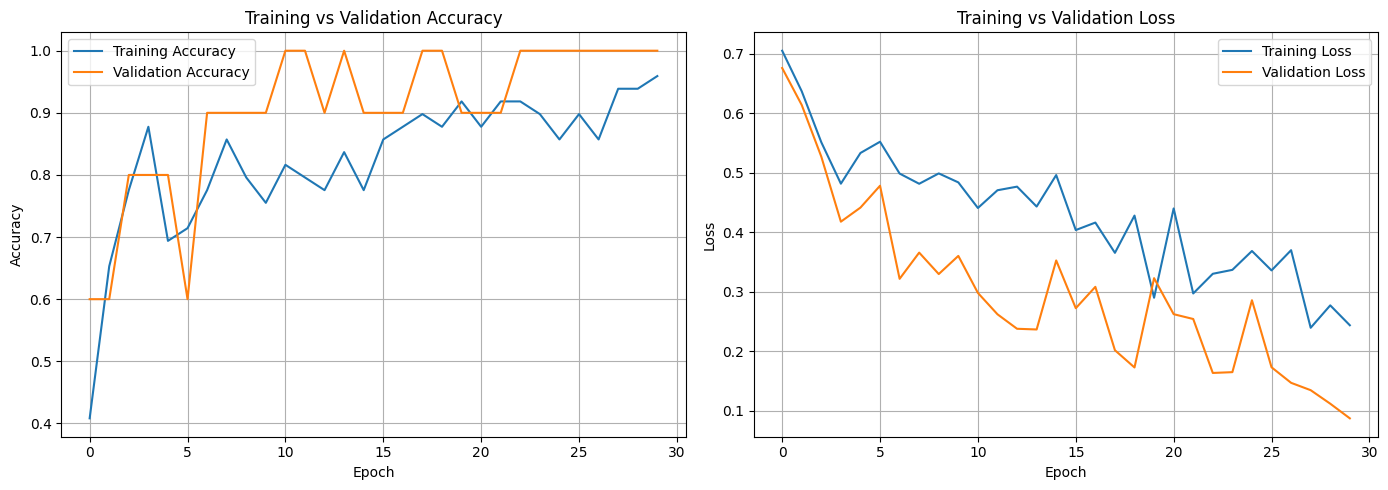

In [37]:
fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 5)
)

# Accuracy graph
axes[0].plot(
    history["train_acc"],
    label="Training Accuracy"
)

axes[0].plot(
    history["val_acc"],
    label="Validation Accuracy"
)

axes[0].set_title("Training vs Validation Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(True)

# Loss graph
axes[1].plot(
    history["train_loss"],
    label="Training Loss"
)

axes[1].plot(
    history["val_loss"],
    label="Validation Loss"
)

axes[1].set_title("Training vs Validation Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

In [38]:
model.load_state_dict(
    torch.load(
        MODEL_PATH,
        map_location=DEVICE
    )
)

model.eval()

print("Best model loaded successfully!")

Best model loaded successfully!


In [39]:
all_labels = []
all_predictions = []
all_probabilities = []

model.eval()

with torch.no_grad():

    for videos, labels in test_loader:

        videos = videos.to(DEVICE)

        outputs = model(videos)

        probabilities = torch.softmax(
            outputs,
            dim=1
        )

        predictions = torch.argmax(
            probabilities,
            dim=1
        )

        all_labels.extend(
            labels.numpy()
        )

        all_predictions.extend(
            predictions.cpu().numpy()
        )

        all_probabilities.extend(
            probabilities[:, 1].cpu().numpy()
        )


all_labels = np.array(all_labels)
all_predictions = np.array(all_predictions)
all_probabilities = np.array(all_probabilities)

print("Predictions generated!")
print("Number of test videos:", len(all_labels))

Predictions generated!
Number of test videos: 11


In [40]:
print(
    classification_report(
        all_labels,
        all_predictions,
        labels=[0, 1],
        target_names=["Non-Fall", "Fall"],
        zero_division=0
    )
)

              precision    recall  f1-score   support

    Non-Fall       1.00      1.00      1.00         6
        Fall       1.00      1.00      1.00         5

    accuracy                           1.00        11
   macro avg       1.00      1.00      1.00        11
weighted avg       1.00      1.00      1.00        11



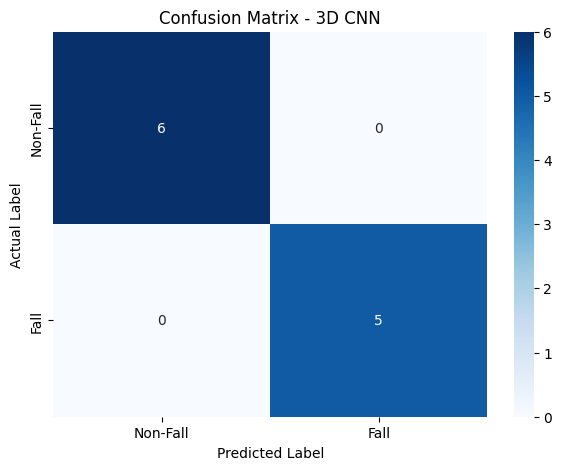

In [42]:
cm = confusion_matrix(
    all_labels,
    all_predictions,
    labels=[0, 1]
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Non-Fall", "Fall"],
    yticklabels=["Non-Fall", "Fall"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.title("Confusion Matrix - 3D CNN")

plt.show()

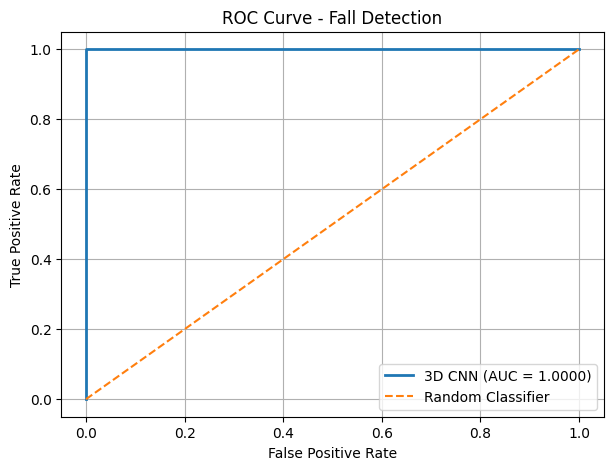

In [43]:
 fpr, tpr, thresholds = roc_curve(
    all_labels,
    all_probabilities
)

auc = roc_auc_score(
    all_labels,
    all_probabilities
)

plt.figure(figsize=(7, 5))

plt.plot(
    fpr,
    tpr,
    linewidth=2,
    label=f"3D CNN (AUC = {auc:.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title("ROC Curve - Fall Detection")

plt.legend()
plt.grid(True)

plt.show()

In [44]:
misclassified = np.where(
    all_labels != all_predictions
)[0]

print("Total test videos:", len(all_labels))

print("Misclassified videos:", len(misclassified))

for idx in misclassified:

    actual = (
        "Fall" if all_labels[idx] == 1
        else "Non-Fall"
    )

    predicted = (
        "Fall" if all_predictions[idx] == 1
        else "Non-Fall"
    )

    print("\nVideo:", valid_paths[test_idx[idx]])

    print("Actual:", actual)

    print("Predicted:", predicted)

    print(
        "Fall probability:",
        round(float(all_probabilities[idx]), 4)
    )

    print("-" * 50)

Total test videos: 11
Misclassified videos: 0
